1.DATASET SETUP

Install the package

In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


Import and download the dataset

In [2]:
from ucimlrepo import fetch_ucirepo

In [61]:
import pandas as pd

In [3]:
heart_disease = fetch_ucirepo(id=45)

Check it worked and we can see that Cleveland Heart Deisease dataset is loaded sucessfully

303 rows/patients
13 predictor features
1 target variable(num)
Missing values in ca and thal


In [8]:
print(heart_disease)

{'data': {'ids': None, 'features':      age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0     63    1   1       145   233    1        2      150      0      2.3   
1     67    1   4       160   286    0        2      108      1      1.5   
2     67    1   4       120   229    0        2      129      1      2.6   
3     37    1   3       130   250    0        0      187      0      3.5   
4     41    0   2       130   204    0        2      172      0      1.4   
..   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
298   45    1   1       110   264    0        0      132      0      1.2   
299   68    1   4       144   193    1        0      141      0      3.4   
300   57    1   4       130   131    0        0      115      1      1.2   
301   57    0   2       130   236    0        2      174      0      0.0   
302   38    1   3       138   175    0        0      173      0      0.0   

     slope   ca  thal  
0        3  0.0   6.0  
1   

2. DATASET INSPECTION

Below code sepaerating dataset into inputs(features) and the output(target) for heart disease machine learning project.
X contains the input variables/features that the machine-learning model will use to make predictions.
These are the 13 predictors such as:
age, sex, cp — chest pain type, trestbps — resting blood pressure, chol — cholesterol, fbs — fasting blood sugar, restecg, thalach — maximum heart rate, exang
oldpeak,slope,ca and thal
So X = information about the patient that the model uses as input.
y contains the answer/output that the model is trying to predict.
So y = the actual outcome/label.

X.shape 
Features shape: (303, 13)
This tells you the number of rows and columns in your features.
It means 303 patient records and 13 input fetures.

y.shape
Target shape: (303, 1)
303 target values
One target value for each patient

For Logistic Regression and Random Forest models, X is what you give the model as the input, while y is what you ask it to learn to predict.

In [4]:
X = heart_disease.data.features
y = heart_disease.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (303, 13)
Target shape: (303, 1)


Before starting the preprocessing, just print out the names of the all columns.

In [7]:
print("Feature columns:")
print(X.columns)

print("\nTarget column:")
print(y.columns)

Feature columns:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='object')

Target column:
Index(['num'], dtype='object')


Next step, Check the missing values.

So there are 6 missing values in the dataset
ca: 4 missing
thal: 2 missing

In [11]:
print(X.isnull().sum())


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64


Check the data types of missing values
ca and thal are float64 because they contain NaN (missing) values. The other variables are integers.

In [12]:
print(X.dtypes)


age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
dtype: object


Check the first 5 rows

In [13]:
print(X.head())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  
0  0.0   6.0  
1  3.0   3.0  
2  2.0   7.0  
3  0.0   3.0  
4  0.0   3.0  


3. TARGET VARIABLE PREPARATION

Next step, inspect the target variable
0 = no presence of heart disease
1, 2, 3, 4 = presence of heart disease
Target distribution was examined to determine the number of observations in each class and assess potential class imbalance

164 : without disease
139 : with disease (55 + 36 + 35 + 13)

So the classes are not exactly equal, but they are reasonably close.
This is important because later, when you train your Logistic Regression and Random Forest models, you need to consider whether the target classes are balanced

In [4]:
print(y.value_counts().sort_index())

num
0      164
1       55
2       36
3       35
4       13
Name: count, dtype: int64


Convert Target into binary

In my project, treating the task as binary classification:

0 → 0 = No disease
1, 2, 3, 4 → 1 = Disease

In [5]:
y_binary = (y["num"] > 0).astype(int)

print(y_binary.value_counts().sort_index())

num
0    164
1    139
Name: count, dtype: int64


In [24]:
y = y_binary

In [26]:
print("Binary target distribution:")
print(y.value_counts().sort_index())


Binary target distribution:
num
0    164
1    139
Name: count, dtype: int64


4. MISSING VALUE CHECK AND HANDLING


The dataset contains missing values in the `ca` and `thal` features. Missing values are handled during the preprocessing stage. Median imputation is applied to numerical features, while the most frequent value is used for categorical features. The preprocessing steps are fitted only on the training data and then applied to the testing data to avoid data leakage.

In [33]:
print("Missing values in features:")
print(X.isnull().sum())

Missing values in features:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64


In [27]:
print("\nTotal missing values:", X.isnull().sum().sum())



Total missing values: 6


5. Duplicate Value check

Duplicate records were checked to ensure that identical patient records were not repeated in the dataset.

In [28]:
data_for_duplicate_check = pd.concat(
    [X, y.rename("target")],
    axis=1
)

print("Number of duplicate rows:", data_for_duplicate_check.duplicated().sum())

Number of duplicate rows: 0


6. Train-Test Split

The dataset was divided into training and testing sets using an 80:20 ratio. The training set is used to develop the machine-learning models, while the testing set remains unseen until model evaluation.

Stratified sampling was used to maintain a similar proportion of the two target classes in both datasets.


In [29]:
from sklearn.model_selection import train_test_split

Check shapes

In [30]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (303, 13)
Target shape: (303,)


Check binary Target

In [34]:
print("Binary target distribution:")
print(y.value_counts().sort_index())

Binary target distribution:
num
0    164
1    139
Name: count, dtype: int64


Perform the split

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Check shapes

In [36]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (242, 13)
X_test shape: (61, 13)
y_train shape: (242,)
y_test shape: (61,)


Check class distribution

In [37]:
print("Training target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training target distribution:
num
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
num
0    33
1    28
Name: count, dtype: int64


7. Feature Encoding, Imputation and Scaling
create a proper preprocessing pipeline, this allows to:
impute missing values
one-hot encode categorical variables
scale numerical variables
fit everything using training data only
apply exactly the same transformations to the test data



Identify numerical features

In [38]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

Identify categorical features

In [39]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

Import preprocessing tools

In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

Create numerical preprocessing pipeline
Numerical data -> Median Imputation -> StandardScaler

In [41]:
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

Create categorical preprocessing pipeline
Categorical data -> Missing-value handling -> One-Hot Encoding

In [42]:
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=False
        ))
    ]
)

Combine both pipelines

In [43]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_pipeline,
            numerical_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)

Fit preprocessing on training data

fit means the imputer, scaler and encoder learn their values from X_train only

In [44]:
X_train_processed = preprocessor.fit_transform(X_train)

Tranform testing data

tranform the test data. This means the test dataset remains unseen during fitting.

X_train ->fit_transform() -> X_train_processed -> X_test -> transform() -> X_test_processed

This helps to avoid data leakage

In [45]:
X_test_processed = preprocessor.transform(X_test)

Check preprocessed data shape

Get more than 13 columns because categorical variables such as cp, thal, etc. are converted into multiple one-hot encoded columns.

In [46]:
print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (242, 20)
Processed X_test shape: (61, 20)


Get processed feature names

In [47]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print("\nProcessed feature names:")
print(feature_names)

Number of processed features: 20

Processed feature names:
['num__age' 'num__trestbps' 'num__chol' 'num__thalach' 'num__oldpeak'
 'cat__sex_1.0' 'cat__cp_2.0' 'cat__cp_3.0' 'cat__cp_4.0' 'cat__fbs_1.0'
 'cat__restecg_1.0' 'cat__restecg_2.0' 'cat__exang_1.0' 'cat__slope_2.0'
 'cat__slope_3.0' 'cat__ca_1.0' 'cat__ca_2.0' 'cat__ca_3.0'
 'cat__thal_6.0' 'cat__thal_7.0']


Convert processed data back to DataFrames

In [48]:
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

Check the processed data

In [49]:
print(X_train_processed.head())

     num__age  num__trestbps  num__chol  num__thalach  num__oldpeak  \
180 -0.729485      -0.395692   0.458139      0.708371     -0.445445   
208  0.050166      -0.054513   0.230598      0.222495     -0.891627   
167 -0.061212       0.059213   0.723605      0.399178     -0.891627   
105 -0.061212      -1.305501   1.121803      0.266666     -0.891627   
297  0.272924       0.514117  -0.167601     -1.190962     -0.713154   

     cat__sex_1.0  cat__cp_2.0  cat__cp_3.0  cat__cp_4.0  cat__fbs_1.0  \
180           1.0          0.0          0.0          1.0           0.0   
208           1.0          1.0          0.0          0.0           0.0   
167           0.0          1.0          0.0          0.0           1.0   
105           1.0          1.0          0.0          0.0           0.0   
297           0.0          0.0          0.0          1.0           0.0   

     cat__restecg_1.0  cat__restecg_2.0  cat__exang_1.0  cat__slope_2.0  \
180               0.0               1.0             0

Check the numerical scaling

In [50]:
print("Training numerical feature means:")
print(X_train_processed[
    [f"num__{feature}" for feature in numerical_features]
].mean())

Training numerical feature means:
num__age        -2.211271e-16
num__trestbps   -3.642633e-16
num__chol        1.761676e-16
num__thalach     2.293849e-17
num__oldpeak    -1.590462e-18
dtype: float64


In [51]:
print("\nTraining numerical feature standard deviations:")
print(X_train_processed[
    [f"num__{feature}" for feature in numerical_features]
].std())


Training numerical feature standard deviations:
num__age         1.002073
num__trestbps    1.002073
num__chol        1.002073
num__thalach     1.002073
num__oldpeak     1.002073
dtype: float64


8. Model Development

Two classification models were developed to predict the presence of heart disease: Logistic Regression and Random Forest. Both models were trained using the processed training dataset. The testing dataset was kept unseen for model evaluation.

8.1 Logistic Regression

Import Logistic regression

In [52]:
from sklearn.linear_model import LogisticRegression

Create the model

Logistic Regression uses an iterative optimisation process. 1000 gives the model enough iterations to converge without getting a convergence warning.

In [54]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

Train logistic Regression

In [55]:
logistic_model.fit(
    X_train_processed,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


Check that Logistic Regression was trained

In [56]:
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


8.2 Random Forest

Import Random Forest

In [57]:
from sklearn.ensemble import RandomForestClassifier

Create the model

The Random Forest will build 100 decision trees and combine their predictions.

random_state=42 ensures that your results are reproducible.

In [58]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

Train Random Forest

In [59]:
random_forest_model.fit(
    X_train_processed,
    y_train
)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Check that Random Forest was trained

In [60]:
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


9. Model Evaluation

The Logistic Regression and Random Forest models were evaluated using the unseen testing dataset. Accuracy, precision, recall, F1-score and ROC-AUC were used to compare model performance. Confusion matrices were also generated to examine correct and incorrect classifications.

Import evaluation metrics

In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

Generate predictions from Logistic regression

This generates the predicted class:
0 = no disease
1 = disease

The [:, 1] selects the probability of the disease class (1).

In [63]:
y_pred_logistic = logistic_model.predict(X_test_processed)

In [64]:
y_prob_logistic = logistic_model.predict_proba(X_test_processed)[:, 1]

Generate predictions from Random Forest

In [65]:
y_pred_rf = random_forest_model.predict(X_test_processed)

In [66]:
y_prob_rf = random_forest_model.predict_proba(X_test_processed)[:, 1]

Evaluvate Logistic Regression

In [67]:
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic)
logistic_recall = recall_score(y_test, y_pred_logistic)
logistic_f1 = f1_score(y_test, y_pred_logistic)
logistic_roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1-score :", logistic_f1)
print("ROC-AUC  :", logistic_roc_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.8688524590163934
Precision: 0.8333333333333334
Recall   : 0.8928571428571429
F1-score : 0.8620689655172413
ROC-AUC  : 0.9621212121212122


Evaluvate Random forest


In [68]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1-score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

Random Forest Results
---------------------
Accuracy : 0.8688524590163934
Precision: 0.8333333333333334
Recall   : 0.8928571428571429
F1-score : 0.8620689655172413
ROC-AUC  : 0.9442640692640693


Compare both models

In [69]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [logistic_accuracy, rf_accuracy],
    "Precision": [logistic_precision, rf_precision],
    "Recall": [logistic_recall, rf_recall],
    "F1-score": [logistic_f1, rf_f1],
    "ROC-AUC": [logistic_roc_auc, rf_roc_auc]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1-score   ROC-AUC
0  Logistic Regression  0.868852   0.833333  0.892857  0.862069  0.962121
1        Random Forest  0.868852   0.833333  0.892857  0.862069  0.944264


Confusion Matrix - Logistic regression

Where:

TN = correctly predicted no disease
FP = predicted disease when there was no disease
FN = predicted no disease when disease was present
TP = correctly predicted disease

In [70]:
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

print("Logistic Regression Confusion Matrix:")
print(cm_logistic)

Logistic Regression Confusion Matrix:
[[28  5]
 [ 3 25]]


Confusion Matrix - Random forest

In [71]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[28  5]
 [ 3 25]]


Classification Report - Logistic Regression

In [73]:
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_logistic))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.85      0.88        33
           1       0.83      0.89      0.86        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



Classification Report - Random Forest

In [72]:
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.85      0.88        33
           1       0.83      0.89      0.86        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



ROC-AUC

In [74]:
print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1-score :", logistic_f1)
print("ROC-AUC  :", logistic_roc_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.8688524590163934
Precision: 0.8333333333333334
Recall   : 0.8928571428571429
F1-score : 0.8620689655172413
ROC-AUC  : 0.9621212121212122


In [75]:
print("Random Forest Results")
print("---------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1-score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

Random Forest Results
---------------------
Accuracy : 0.8688524590163934
Precision: 0.8333333333333334
Recall   : 0.8928571428571429
F1-score : 0.8620689655172413
ROC-AUC  : 0.9442640692640693


In [76]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [logistic_accuracy, rf_accuracy],
    "Precision": [logistic_precision, rf_precision],
    "Recall": [logistic_recall, rf_recall],
    "F1-score": [logistic_f1, rf_f1],
    "ROC-AUC": [logistic_roc_auc, rf_roc_auc]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1-score   ROC-AUC
0  Logistic Regression  0.868852   0.833333  0.892857  0.862069  0.962121
1        Random Forest  0.868852   0.833333  0.892857  0.862069  0.944264


Both models produced exactly the same:

Accuracy: 86.89%
Precision: 83.33%
Recall: 89.29%
F1-score: 86.21%
Confusion matrix: [[28, 5], [3, 25]]

The difference is ROC-AUC:
Logistic Regression = 0.9621
Random Forest       = 0.9443

Therefore, based on your predefined evaluation metrics, Logistic Regression is the better-performing model on this test set because it has the higher ROC-AUC while matching Random Forest on all the other reported metrics.

Final decision:

Logistic Regression as the best-performing model for subsequent Explainable AI (XAI) analysis.


10. Explainable AI(XAI) - SHAP

SHAP (SHapley Additive exPlanations) was used to explain the predictions of the selected Logistic Regression model. SHAP provides global feature importance by measuring the average contribution of features across predictions and local explanations by showing how individual features influence a specific prediction.

Install SHAP

In [77]:
%pip install shap

Import SHAP

In [78]:
import shap

Create the SHAP explainer

Selected model is Logistic Regression, we can use SHAP's general Explainer with the trained linear model and the processed training data.

In [79]:
explainer = shap.Explainer(
    logistic_model,
    X_train_processed
)

Calculate SHAP values for the test data

In [80]:
shap_values = explainer(X_test_processed)

Check the result

In [81]:
print(shap_values)

.values =
array([[ 4.33714007e-03,  1.14816564e-01,  5.27250261e-02, ...,
        -2.22765445e-02, -1.84465253e-03, -5.42504206e-01],
       [ 1.32665461e-02,  4.66132891e-01, -7.90875391e-02, ...,
        -2.22765445e-02,  5.96437652e-02, -5.42504206e-01],
       [-5.86789539e-03, -1.29348284e-02,  6.74389868e-03, ...,
        -2.22765445e-02, -1.84465253e-03, -5.42504206e-01],
       ...,
       [ 9.43965781e-03,  6.69097915e-02, -5.51773528e-03, ...,
        -2.22765445e-02, -1.84465253e-03, -5.42504206e-01],
       [-7.65377660e-04,  1.90030196e-02,  2.70369029e-01, ...,
        -2.22765445e-02, -1.84465253e-03, -5.42504206e-01],
       [ 1.83690638e-02, -1.29348284e-02,  2.09060859e-01, ...,
         1.09155068e+00, -1.84465253e-03, -5.42504206e-01]],
      shape=(61, 20))

.base_values =
array([-0.21276241, -0.21276241, -0.21276241, -0.21276241, -0.21276241,
       -0.21276241, -0.21276241, -0.21276241, -0.21276241, -0.21276241,
       -0.21276241, -0.21276241, -0.21276241, -0.21

Check the SHAP dimensions

In [82]:
print("SHAP values shape:", shap_values.values.shape)
print("Test data shape:", X_test_processed.shape)

SHAP values shape: (61, 20)
Test data shape: (61, 20)


Global Feature Importance — Bar Plot

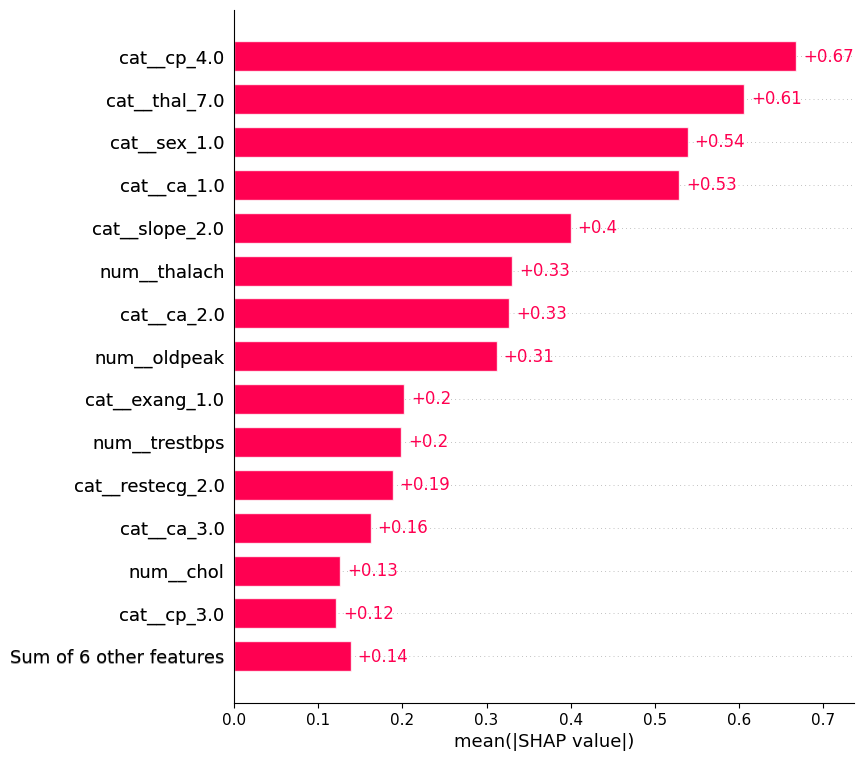

In [83]:
shap.plots.bar(shap_values, max_display=15)

Global SHAP Summary / Beeswarm Plot

Positive SHAP value → pushes the model toward the positive class, which in your project is heart disease = 1.
Negative SHAP value → pushes the model toward no disease = 0.
The further a point is from zero, the stronger its contribution.

For your final report, this plot is particularly useful because it gives both:

feature importance + direction of influence.

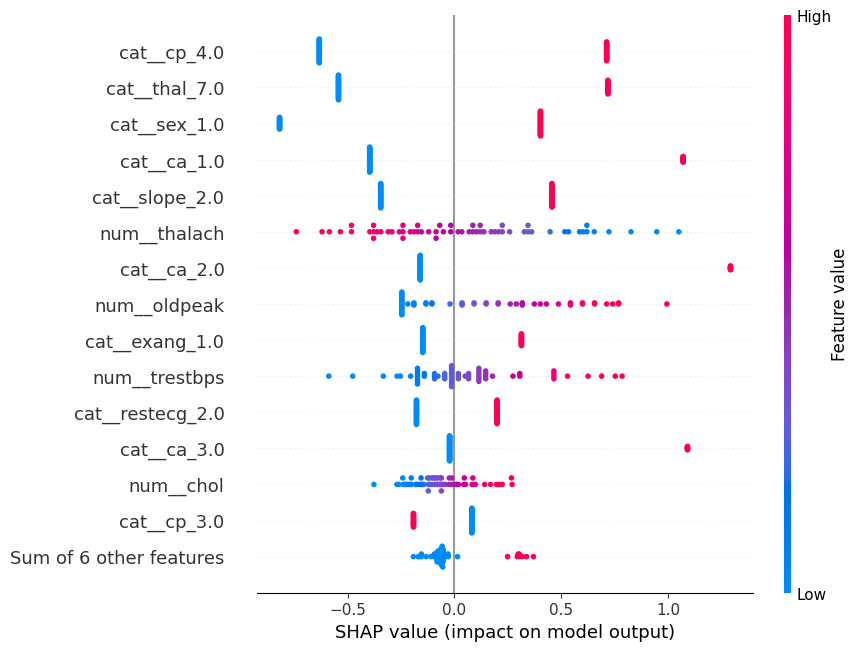

In [84]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

Local Explanation - Individual Patient

In [85]:
patient_index = 0

In [86]:
patient_prediction = logistic_model.predict(
    X_test_processed.iloc[[patient_index]]
)[0]

patient_probability = logistic_model.predict_proba(
    X_test_processed.iloc[[patient_index]]
)[0, 1]

print("Predicted class:", patient_prediction)
print("Probability of heart disease:", patient_probability)
print("Actual class:", y_test.iloc[patient_index])

Predicted class: 0
Probability of heart disease: 0.2505880628739405
Actual class: 0


Create the local SHAP explanation

In [87]:
patient_shap = shap_values[patient_index]

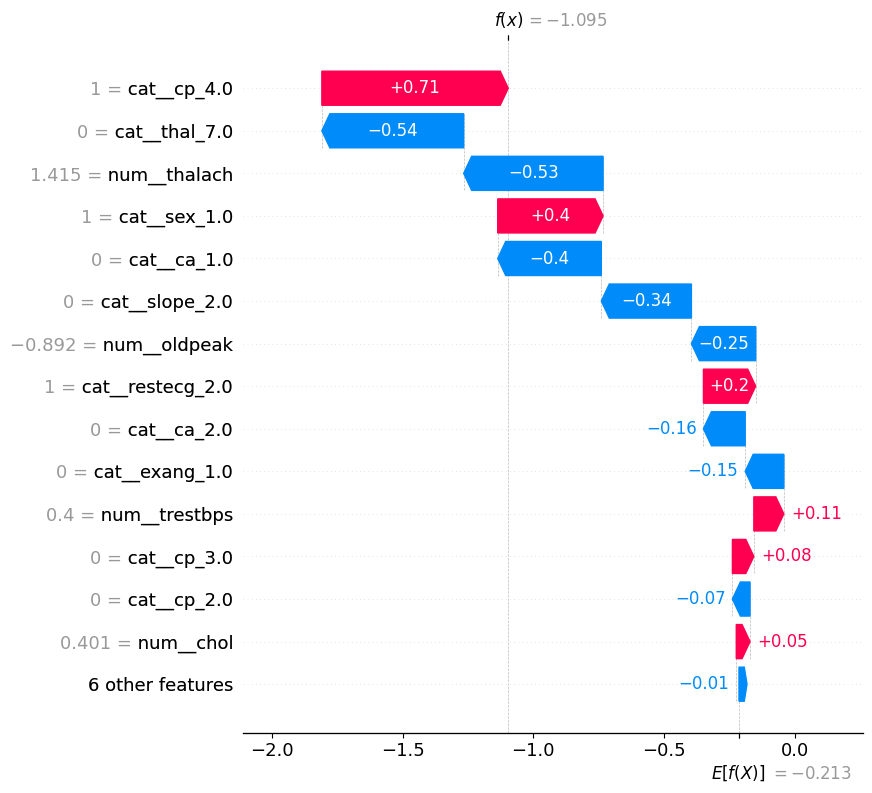

In [88]:
shap.plots.waterfall(
    patient_shap,
    max_display=15
)

Show the individual patient's input values

In [89]:
print("Patient feature values:")
print(X_test.iloc[patient_index])

Patient feature values:
age          59.0
sex           1.0
cp            4.0
trestbps    138.0
chol        271.0
fbs           0.0
restecg       2.0
thalach     182.0
exang         0.0
oldpeak       0.0
slope         1.0
ca            0.0
thal          3.0
Name: 219, dtype: float64


In [90]:
print("\nActual class:", y_test.iloc[patient_index])
print("Predicted class:", patient_prediction)
print("Predicted probability of heart disease:", patient_probability)


Actual class: 0
Predicted class: 0
Predicted probability of heart disease: 0.2505880628739405
